In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("cs1090a_hw5.ipynb")

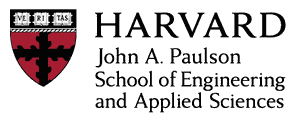

# CS1090A Introduction to Data Science
## Homework 5: Which students will finish their degree?
### Decision trees & ensembles

**Harvard University**<br/>
**Fall 2026**<br/>
**Instructors**: Pavlos Protopapas, Kevin Rader, and Chris Gumb

<hr style="height:2.4pt">

## Instructions

This assignment is graded out of 70 points, for CS1090A and AC209A students alike.

This assignment is open-ended. You build two classifiers for the same problem: a single decision tree in Part 2 and an ensemble of your choice in Part 3. Each question names a decision, such as how to prepare the data, how to choose and tune the model, or how to interpret it, and you make that decision yourself. There is usually more than one defensible choice. You are graded on whether each choice is justified with evidence from your own output, not on whether it matches the staff's choice. Add code and markdown cells as you need them, and answer each written response in a short paragraph.

**Running the notebook**

- Your submitted notebook must run in order after restarting the kernel, using only the files in this bundle, in under 35 minutes. The last cell prints the runtime.
- Re-running your notebook must reproduce your submission files exactly, so set `random_state` wherever randomness enters.

**Kaggle**

Each model has a Kaggle competition, scored by macro-F1 (defined in Part 1). Each Kaggle question (Q2.4 and Q3.4) is worth 5 points, pass/fail: you receive them if you submitted, if re-running your notebook reproduces the file you upload to Gradescope, and if your score beats the floor benchmark shown on the leaderboard. Your rank does not affect your grade. The competitions' Overview and Rules pages give the details. The four students ranked highest on the ensemble competition's private leaderboard win a dinner with Kevin, Pavlos, and Chris.

**What to upload to Gradescope:** the notebook and the two files `submission_dt.csv` and `submission_ensemble.csv` from your `submissions/` folder, as three separate files (not a zip).

**Use of AI tools**

You may use AI tools. You are accountable for everything you submit: you must understand it and be able to explain it.

- Written answers must be your own words.
- Quizzes and midterms ask you to explain and apply these methods.

All plots must have axis labels, a descriptive title, and a legend when colors, symbols, or reference lines distinguish information.

In [2]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

notebook_start = time.time()

# Setup. The data and a supplied function

The data come from a public dataset of 4,424 students at the Polytechnic Institute of Portalegre, Portugal, described in the paper by Martins et al. in `data/early_prediction_of_students_performance.pdf`. Each row is one student, and the 21 columns describe the student at the time they enrolled. The outcome is one of three classes: the student dropped out (`Dropout`), was still enrolled at the end of the program's normal duration (`Enrolled`), or graduated (`Graduate`).

The staff have already removed the columns that would not be known at enrollment, such as first-semester grades. Those columns describe what happened after enrollment, so a model that used them would not be predicting at enrollment at all. Removing a column like this prevents **data leakage**.

You have the outcomes for the 3,318 training rows. The 1,106 rows in `X_test.csv` have no outcomes; the Kaggle competitions score your predictions for them. Because you never see the test outcomes, **every number you report in this notebook comes from the training rows**. How you estimate a model's performance on students it has not seen is one of your decisions.

<details><summary><b>Column descriptions</b> (click to expand)</summary>

| Column | Description |
|---|---|
| `Marital status` | 1 single, 2 married, 3 widower, 4 divorced, 5 facto union, 6 legally separated |
| `Application mode` | how the student applied: 1 1st phase, general contingent; 2 Ordinance No. 612/93; 5 1st phase, special contingent (Azores); 7 holders of other higher courses; 10 Ordinance No. 854-B/99; 15 international student (bachelor); 16 1st phase, special contingent (Madeira); 17 2nd phase, general contingent; 18 3rd phase, general contingent; 26 Ordinance No. 533-A/99 (different plan); 27 Ordinance No. 533-A/99 (other institution); 39 over 23 years old; 42 transfer; 43 change of course; 44 technological specialization diploma holders; 51 change of institution/course; 53 short cycle diploma holders; 57 change of institution/course (international) |
| `Application order` | the rank of this program among the student's choices, from 0 (first choice) to 9 (last choice) |
| `Course` | the degree program: 33 Biofuel Production Technologies, 171 Animation and Multimedia Design, 8014 Social Service (evening), 9003 Agronomy, 9070 Communication Design, 9085 Veterinary Nursing, 9119 Informatics Engineering, 9130 Equinculture, 9147 Management, 9238 Social Service, 9254 Tourism, 9500 Nursing, 9556 Oral Hygiene, 9670 Advertising and Marketing Management, 9773 Journalism and Communication, 9853 Basic Education, 9991 Management (evening) |
| `Daytime/evening attendance` | 1 daytime, 0 evening |
| `Previous qualification` | type of the student's previous qualification (codes for levels of secondary schooling, higher-education degrees and technical programs; see the paper) |
| `Previous qualification (grade)` | grade of the previous qualification, on a 0 to 200 scale |
| `Nationality` | coded nationality, for example 1 Portuguese, 6 Spanish, 41 Brazilian, 62 Romanian |
| `Mother's qualification`, `Father's qualification` | each parent's education (codes for levels of schooling and degrees) |
| `Mother's occupation`, `Father's occupation` | each parent's occupation category (codes for groups such as specialists, technicians, administrative staff, service workers, skilled and unskilled workers) |
| `Admission grade` | the student's admission grade, on a 0 to 200 scale |
| `Displaced` | 1 if the student moved to attend the institution, 0 if not |
| `Educational special needs` | 1 yes, 0 no |
| `Debtor` | 1 if the student owed money to the institution, 0 if not |
| `Tuition fees up to date` | 1 yes, 0 no |
| `Gender` | 1 male, 0 female |
| `Scholarship holder` | 1 yes, 0 no |
| `Age at enrollment` | the student's age in years when they enrolled |
| `International` | 1 yes, 0 no |
| `Target` (in `y_train.csv`) | the outcome at the end of the program's normal duration: `Dropout`, `Enrolled` (still enrolled, not yet graduated) or `Graduate` |

</details>

In [3]:
# Supplied: the data and the function that writes Kaggle submission files. Do not change this cell.
X_train = pd.read_csv("data/X_train.csv")
y_train = pd.read_csv("data/y_train.csv")["Target"]
X_test = pd.read_csv("data/X_test.csv")

CLASSES = ["Dropout", "Enrolled", "Graduate"]
os.makedirs("submissions", exist_ok=True)


def write_submission(predictions, kind):
    """Write one Kaggle submission file. `kind` is "dt" or "ensemble"."""
    column = {"dt": "DT_Predicted", "ensemble": "Ensemble_Predicted"}[kind]
    assert len(predictions) == len(X_test), "predict X_test, all 1,106 rows, in their original order"
    path = f"submissions/submission_{kind}.csv"
    pd.DataFrame({"ID": X_test.index, column: predictions}).to_csv(path, index=False)
    print(f"wrote {path}: {len(predictions)} rows,", pd.Series(predictions).value_counts().to_dict())


print(f"{len(X_train):,} training rows, {len(X_test):,} test rows, {X_train.shape[1]} columns")

3,318 training rows, 1,106 test rows, 21 columns


In [4]:
# Our setup: the scikit-learn pieces we use, one seed for every source of randomness, and the column groups.
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 209
NOMINAL = ["Marital status", "Application mode", "Course", "Previous qualification", "Nationality",
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARY = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
NUMERIC = ["Application order", "Previous qualification (grade)", "Admission grade", "Age at enrollment"]
assert sorted(NOMINAL + BINARY + NUMERIC) == sorted(X_train.columns)
pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
plt.rcParams["font.size"] = 11

# Part 1. The data and the leaderboard metric

**Precision** for a class is the share of students predicted to be in that class who really are in it, and **recall** for a class is the share of students in that class whom the model predicts to be in it. The **F1 score** for a class combines the two as $2 \cdot \text{precision} \cdot \text{recall} / (\text{precision} + \text{recall})$, which is high only when both are high. **Macro-F1** is the average of the three classes' F1 scores, with each class counted equally however many students it has. Both Kaggle competitions score macro-F1.

## Q1.1. Explore the data

**5 points**

Explore the training data in whatever way you judge most useful for the modeling in Parts 2 and 3. In the written response, summarize what you found and how it will shape your modeling decisions.

,students,share
Target,,
Dropout,1066,0.321
Enrolled,595,0.179
Graduate,1657,0.499


Target,n,Dropout,Enrolled,Graduate
Tuition fees up to date = 0,397,0.866,0.081,0.053
Tuition fees up to date = 1,2921,0.247,0.193,0.560
Debtor = 0,2944,0.279,0.181,0.540
Debtor = 1,374,0.655,0.166,0.179
Scholarship holder = 0,2483,0.388,0.200,0.412
Scholarship holder = 1,835,0.122,0.119,0.759
Gender = 0,2154,0.252,0.170,0.578
Gender = 1,1164,0.449,0.197,0.354


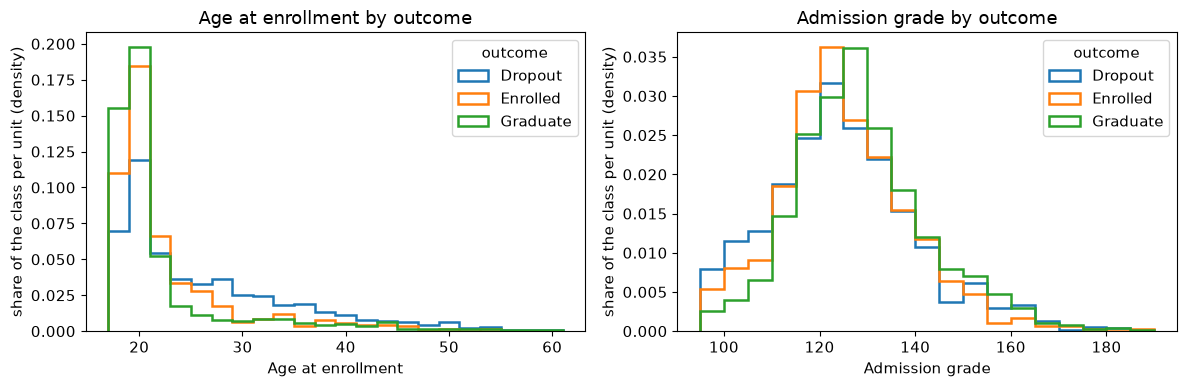

,Age at enrollment,Admission grade
Target,,
Dropout,23.000,123.374
Enrolled,20.000,123.663
Graduate,19.000,127.350


,levels,levels with < 30 students,X_test rows with a code not in training
Marital status,6,3,0
Application mode,18,9,0
Course,17,1,0
Previous qualification,16,10,1
Nationality,18,17,4
Mother's qualification,27,18,2
Father's qualification,30,22,4
Mother's occupation,31,21,1
Father's occupation,41,29,5


dropout share by course, lowest and highest three:


,n,dropout share
Course,,
9500,568,0.146
9238,270,0.185
9070,167,0.222
9119,126,0.532
9130,110,0.573
33,10,0.700


missing values: 0 in training, 0 in test; duplicated training rows: 0; X_test rows with any unseen code: 16
International == (Nationality != 1) on 3318 of 3318 rows
Courses of the evening students: [8014, 9991] | evening share in those courses: 1.0
youngest student who applied through mode 39 (over 23 years old): 24


In [5]:
# Q1.1: class balance, the columns that separate the classes, and what the coded columns look like.
counts = y_train.value_counts().reindex(CLASSES)
display(pd.DataFrame({"students": counts, "share": (counts / len(y_train)).round(3)}))


def outcome_shares(col):
    """Outcome shares within each value of a column, with the number of students."""
    table = pd.crosstab(X_train[col], y_train, normalize="index")[CLASSES].round(3)
    table.insert(0, "n", X_train[col].value_counts().sort_index())
    table.index = [f"{col} = {v}" for v in table.index]
    return table


display(pd.concat([outcome_shares(c) for c in ["Tuition fees up to date", "Debtor", "Scholarship holder", "Gender"]]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, bins in zip(axes, ["Age at enrollment", "Admission grade"], [np.arange(17, 63, 2), np.arange(95, 191, 5)]):
    for cls in CLASSES:
        ax.hist(X_train.loc[y_train == cls, col], bins=bins, density=True, histtype="step", linewidth=1.8, label=cls)
    ax.set(xlabel=col, ylabel="share of the class per unit (density)", title=f"{col} by outcome")
    ax.legend(title="outcome")
plt.tight_layout()
plt.show()
display(X_train.groupby(y_train)[["Age at enrollment", "Admission grade"]].median().reindex(CLASSES))

codes = pd.DataFrame({
    "levels": X_train[NOMINAL].nunique(),
    "levels with < 30 students": [(X_train[c].value_counts() < 30).sum() for c in NOMINAL],
    "X_test rows with a code not in training": [(~X_test[c].isin(X_train[c])).sum() for c in NOMINAL]})
display(codes)
by_course = pd.DataFrame({"n": X_train["Course"].value_counts(),
                          "dropout share": pd.crosstab(X_train["Course"], y_train, normalize="index")["Dropout"]})
print("dropout share by course, lowest and highest three:")
display(by_course.sort_values("dropout share").iloc[[0, 1, 2, -3, -2, -1]])
unseen_rows = (~X_test[NOMINAL].apply(lambda col: col.isin(X_train[col.name]))).any(axis=1)
print(f"missing values: {X_train.isna().sum().sum()} in training, {X_test.isna().sum().sum()} in test; "
      f"duplicated training rows: {X_train.duplicated().sum()}; X_test rows with any unseen code: {unseen_rows.sum()}")

# Columns that repeat information another column already carries.
print("International == (Nationality != 1) on",
      ((X_train["International"] == 1) == (X_train["Nationality"] != 1)).sum(), "of", len(X_train), "rows")
print("Courses of the evening students:",
      sorted(X_train.loc[X_train["Daytime/evening attendance"] == 0, "Course"].unique().tolist()),
      "| evening share in those courses:",
      (X_train.loc[X_train["Course"].isin([8014, 9991]), "Daytime/evening attendance"] == 0).mean())
print("youngest student who applied through mode 39 (over 23 years old):",
      X_train.loc[X_train["Application mode"] == 39, "Age at enrollment"].min())

**Written response: Q1.1**

- Enrolled is only 17.9% of the 3,318 students (Graduate 49.9%, Dropout 32.1%), but macro-F1 gives it a third of the score. So both models get class weights, and we check what the weights do.
- Money and scholarships separate the classes most. Of the 397 students behind on tuition, 86.6% dropped out (24.7% of the rest). Debtors dropped out 65.5% of the time, and scholarship holders graduated 75.9% of the time (41.2% without one). Dropouts are older (median 23 vs 19 for graduates) and more often male (44.9% of men vs 25.2% of women), while admission grades barely differ. The dropout share by program runs from 0.146 (Nursing, 568 students) to 0.573 (course 9130, 110 students).
- Nothing is missing or duplicated, so nothing needs imputing. Nine columns are unordered codes with many rare levels (29 of the 41 father's occupation codes have under 30 students), and 16 test rows have a code never seen in training, so the encoding is a real choice (Q2.1). Some columns copy others. International equals "Nationality is not 1" on all 3,318 rows, evening attendance happens only in courses 8014 and 9991, and nobody in application mode 39 (over 23) is younger than 24. Copies split importance between them, which matters when we interpret the models.

## Q1.2. Establish a baseline

**3 points**

Before building models, decide what a model has to beat to be useful on this problem. Compute that baseline and, in the written response, explain why it is the right point of comparison.

In [6]:
# Q1.2: the split behind every estimate in this notebook, and three rules that use no model.
X_dev, X_hold, y_dev, y_hold = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                                random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"development rows {len(X_dev):,}, holdout rows {len(X_hold):,}")


def fee_rule(X):
    """Dropout if the student is behind on tuition or owes the institution money, else Graduate."""
    return np.where((X["Tuition fees up to date"] == 0) | (X["Debtor"] == 1), "Dropout", "Graduate")


baselines = {}
for name, dummy in {"always Graduate (majority class)": DummyClassifier(strategy="most_frequent"),
                    "guess in proportion to class shares": DummyClassifier(strategy="stratified", random_state=SEED)}.items():
    pred = dummy.fit(X_dev, y_dev).predict(X_hold)
    baselines[name] = {"CV macro-F1": cross_val_score(dummy, X_dev, y_dev, cv=cv, scoring="f1_macro").mean(),
                       "holdout macro-F1": f1_score(y_hold, pred, average="macro"),
                       "holdout accuracy": np.mean(pred == y_hold)}
fold_rule_cv = [f1_score(y_dev.iloc[val], fee_rule(X_dev.iloc[val]), average="macro") for _, val in cv.split(X_dev, y_dev)]
baselines["fee rule: behind on fees or debtor -> Dropout"] = {
    "CV macro-F1": np.mean(fold_rule_cv), "holdout macro-F1": f1_score(y_hold, fee_rule(X_hold), average="macro"),
    "holdout accuracy": np.mean(fee_rule(X_hold) == y_hold)}
baseline_table = pd.DataFrame.from_dict(baselines, orient="index")
display(baseline_table.round(3))
print("expected macro-F1 of guessing in proportion to the class shares: 1/3 = 0.333 "
      "(each class's precision and recall both equal its share)")
rule_f1 = f1_score(y_hold, fee_rule(X_hold), average=None, labels=CLASSES, zero_division=0)
print("fee rule, holdout F1 by class:", dict(zip(CLASSES, rule_f1.round(3).tolist())))

development rows 2,654, holdout rows 664


,CV macro-F1,holdout macro-F1,holdout accuracy
always Graduate (majority class),0.222,0.222,0.500
guess in proportion to class shares,0.326,0.349,0.410
fee rule: behind on fees or debtor -> Dropout,0.411,0.402,0.596


expected macro-F1 of guessing in proportion to the class shares: 1/3 = 0.333 (each class's precision and recall both equal its share)
fee rule, holdout F1 by class: {'Dropout': 0.492, 'Enrolled': 0.0, 'Graduate': 0.713}


**Written response: Q1.2**

- Always predicting Graduate gets 0.500 accuracy but only 0.222 macro-F1, because the other two classes score 0. That is why accuracy is the wrong yardstick here. Guessing in proportion to the class shares has an expected macro-F1 of exactly 1/3, since each class's precision and recall both equal its share. Our one draw got 0.349 on the holdout.
- Our bar is a rule a registrar could apply without a model: Dropout if the student is behind on fees or in debt, otherwise Graduate. It scores 0.402 on the holdout and 0.411 in CV. A model that can't beat two columns and an if-statement isn't worth fitting. The rule never predicts Enrolled (F1 0.0), so beating it means catching some of those students. All baselines are scored on the same folds and holdout as the models, so the numbers compare directly.

# Part 2. Model 1: a single decision tree

Your first model is a single decision tree.

## Q2.1. Prepare the data

**5 points**

Prepare the data for your decision tree. In the written response, explain each preprocessing decision you made, including any decision to leave something unchanged, and why it suits a decision tree.

In [7]:
# Q2.1: drop the one column that repeats another, and compare three ways of giving the coded columns to a tree.
KEPT = [c for c in X_train.columns if c != "International"]   # International == (Nationality != 1) on every row
OTHER = [c for c in KEPT if c not in NOMINAL]
raw_codes = make_column_transformer(("passthrough", KEPT), verbose_feature_names_out=False)
one_hot = make_column_transformer(
    (OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist", sparse_output=False), NOMINAL),
    ("passthrough", OTHER), verbose_feature_names_out=False)
# Outcome rates: each code becomes three numbers, the shares of training students with that code who dropped out,
# stayed enrolled and graduated (pulled toward the overall shares when the code is rare). A training row's rates come
# from the other four fifths of the training rows, so no row's rates include its own outcome.
outcome_rates = make_column_transformer(
    (TargetEncoder(target_type="multiclass", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)), NOMINAL),
    ("passthrough", OTHER), verbose_feature_names_out=False)
encodings = {"raw codes": raw_codes, "one-hot": one_hot, "outcome rates": outcome_rates}
print("columns after each encoding:", {name: prep.fit(X_dev, y_dev).transform(X_dev).shape[1] for name, prep in encodings.items()})

rates_demo = pd.DataFrame(outcome_rates.transform(X_dev), columns=outcome_rates.get_feature_names_out(), index=X_dev.index)
demo = rates_demo[["Course_Dropout", "Course_Enrolled", "Course_Graduate"]].groupby(X_dev["Course"]).first()
print("what the tree sees in place of two Course codes (9500 is Nursing, 9119 is Informatics Engineering):")
display(demo.loc[[9500, 9119]])

encoding_cv = {}
for name, prep in encodings.items():
    for leaves in [4, 8, 16, 32]:
        pipe = Pipeline([("prep", prep), ("tree", DecisionTreeClassifier(max_leaf_nodes=leaves, min_samples_leaf=20,
                                                                          class_weight="balanced", random_state=SEED))])
        scores = cross_val_score(pipe, X_dev, y_dev, cv=cv, scoring="f1_macro")
        encoding_cv[(name, leaves)] = f"{scores.mean():.3f} ({scores.std():.3f})"
display(pd.Series(encoding_cv).unstack(0)[list(encodings)].rename_axis("leaves (min_samples_leaf 20, balanced weights)"))

columns after each encoding: {'raw codes': 20, 'one-hot': 90, 'outcome rates': 38}
what the tree sees in place of two Course codes (9500 is Nursing, 9119 is Informatics Engineering):


,Course_Dropout,Course_Enrolled,Course_Graduate
Course,,,
9500,0.143,0.136,0.720
9119,0.545,0.356,0.096


,raw codes,one-hot,outcome rates
"leaves (min_samples_leaf 20, balanced weights)",,,
4,0.490 (0.020),0.490 (0.020),0.497 (0.018)
8,0.505 (0.025),0.520 (0.019),0.551 (0.016)
16,0.518 (0.017),0.515 (0.033),0.542 (0.020)
32,0.514 (0.016),0.519 (0.015),0.527 (0.022)


**Written response: Q2.1**

- The numeric and 0/1 columns stay as they are. A tree only compares a value with a threshold, so scaling or any other order-preserving change gives the same splits, and outliers can't drag a split around. Nothing is missing, so there is nothing to impute.
- We dropped International. It equals "Nationality is not 1" on every row and would only share credit with Nationality. We kept evening attendance and application mode even though they overlap with course and age, because one flag is easier to read than a pair of course columns.
- The nine code columns are categories, so a threshold on a code number groups programs that just happen to have nearby codes. We compared three encodings: raw codes, one-hot columns (codes held by under 30 students pooled, 90 columns), and outcome rates, where each code is replaced by the shares of training students with that code who dropped out, stayed enrolled and graduated (Nursing becomes 0.143, 0.136, 0.720). The rates lead at every tree size we tried, by the most at 8 leaves (0.551, against 0.520 for one-hot and 0.505 for raw codes). One split on a rate can separate every low-graduation program from the rest, which one-hot needs a split per program to do. A training row's rates come from the other four fifths of the training rows, so they never include its own outcome. The encoder is refit inside each CV fold, and a code never seen in training (16 test rows have one) gets the overall shares.

## Q2.2. Choose and tune your tree

**8 points**

Select your final decision tree. In the written response, explain what you tuned and why, how you estimated performance on students the model has not seen, and the evidence that led to your final choice.

,leaves,leaf,weights,mean_test_score,std_test_score,mean_train_score
131,8,30,balanced,0.555,0.015,0.567
128,8,1,balanced,0.552,0.016,0.569
129,8,10,balanced,0.552,0.016,0.569
145,12,10,balanced,0.552,0.017,0.574
139,10,30,balanced,0.551,0.012,0.568
144,12,1,balanced,0.551,0.017,0.573
137,10,10,balanced,0.551,0.012,0.574
130,8,20,balanced,0.551,0.016,0.568


best of 192 settings: 0.555 (fold SD 0.015, SE 0.007) at 8 leaves, leaf size 30, balanced
chosen by the one-SE rule: 6 leaves, leaf size 30, balanced, CV macro-F1 0.549 (fold SD 0.018), training macro-F1 0.564


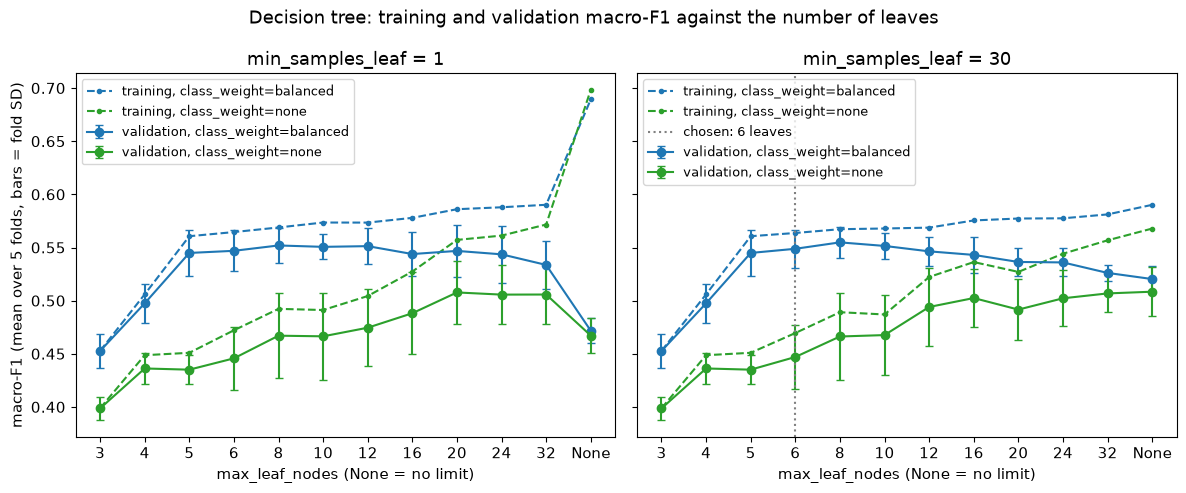

no limit on leaves, leaf size 1, balanced: training 0.689, validation 0.472
class_weight=None: out-of-fold F1 Dropout 0.597, Enrolled 0.043, Graduate 0.711; predicted Enrolled for 1.5% of students


class_weight=balanced: out-of-fold F1 Dropout 0.602, Enrolled 0.351, Graduate 0.698; predicted Enrolled for 24.2% of students
holdout macro-F1 0.525
              precision    recall  f1-score   support

     Dropout      0.665     0.484     0.560       213
    Enrolled      0.276     0.420     0.333       119
    Graduate      0.686     0.678     0.682       332

    accuracy                          0.569       664
   macro avg      0.542     0.527     0.525       664
weighted avg      0.606     0.569     0.580       664



In [8]:
# Q2.2: tune the number of leaves, leaf size and class weights on the five folds; keep the smallest tree within one SE of the best.
tree_pipe = Pipeline([("prep", outcome_rates), ("tree", DecisionTreeClassifier(criterion="gini", random_state=SEED))])
LEAVES = [3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32, None]   # the tree grows its best split first until it has this many leaves
tree_grid = {"tree__max_leaf_nodes": LEAVES,
             "tree__min_samples_leaf": [1, 10, 20, 30, 40, 60, 80, 120],
             "tree__class_weight": [None, "balanced"]}


def cv_table(cv_results):
    """cv_results_ as a DataFrame with plain columns; an unlimited number of leaves is shown as inf."""
    res = pd.DataFrame(cv_results)
    res["leaves"] = pd.to_numeric(res["param_tree__max_leaf_nodes"], errors="coerce").fillna(np.inf)
    res["leaf"] = res["param_tree__min_samples_leaf"].astype(int)
    res["weights"] = res["param_tree__class_weight"].fillna("none").astype(str)
    return res


def one_se_rule(cv_results):
    """Fewest leaves (then largest leaf size) whose mean CV macro-F1 is within one SE of the best mean."""
    res = cv_table(cv_results)
    best = res["mean_test_score"].idxmax()
    floor = res.loc[best, "mean_test_score"] - res.loc[best, "std_test_score"] / np.sqrt(cv.get_n_splits())
    return res[res["mean_test_score"] >= floor].sort_values(["leaves", "leaf"], ascending=[True, False]).index[0]


tree_search = GridSearchCV(tree_pipe, tree_grid, scoring="f1_macro", cv=cv, refit=one_se_rule,
                           return_train_score=True, n_jobs=-1).fit(X_dev, y_dev)
tree_res = cv_table(tree_search.cv_results_)
best_row = tree_res.loc[tree_res["mean_test_score"].idxmax()]
chosen_row = tree_res.loc[tree_search.best_index_]
cols = ["leaves", "leaf", "weights", "mean_test_score", "std_test_score", "mean_train_score"]
display(tree_res.sort_values("mean_test_score", ascending=False)[cols].head(8)
        .assign(leaves=lambda d: d["leaves"].map(lambda v: "None" if np.isinf(v) else int(v))))
print(f"best of {len(tree_res)} settings: {best_row['mean_test_score']:.3f} (fold SD {best_row['std_test_score']:.3f}, "
      f"SE {best_row['std_test_score'] / np.sqrt(5):.3f}) at {best_row['leaves']:g} leaves, leaf size {best_row['leaf']}, {best_row['weights']}")
print(f"chosen by the one-SE rule: {chosen_row['leaves']:g} leaves, leaf size {chosen_row['leaf']}, {chosen_row['weights']}, "
      f"CV macro-F1 {chosen_row['mean_test_score']:.3f} (fold SD {chosen_row['std_test_score']:.3f}), "
      f"training macro-F1 {chosen_row['mean_train_score']:.3f}")

# Validation and training curves against the number of leaves: leaves of any size (left) and the chosen leaf size (right).
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
xpos = {v: i for i, v in enumerate([np.inf if v is None else v for v in LEAVES])}
for ax, leaf in zip(axes, [1, chosen_row["leaf"]]):
    for weights, color in [("balanced", "tab:blue"), ("none", "tab:green")]:
        rows = tree_res[(tree_res["leaf"] == leaf) & (tree_res["weights"] == weights)].sort_values("leaves")
        x = rows["leaves"].map(xpos)
        ax.errorbar(x, rows["mean_test_score"], yerr=rows["std_test_score"], color=color, marker="o", capsize=3,
                    label=f"validation, class_weight={weights}")
        ax.plot(x, rows["mean_train_score"], color=color, linestyle="--", marker=".", label=f"training, class_weight={weights}")
    if leaf == chosen_row["leaf"]:
        ax.axvline(xpos[chosen_row["leaves"]], color="grey", linestyle=":", label=f"chosen: {chosen_row['leaves']:g} leaves")
    ax.set_xticks(list(xpos.values()), ["None" if np.isinf(v) else f"{v:g}" for v in xpos])
    ax.set(xlabel="max_leaf_nodes (None = no limit)", title=f"min_samples_leaf = {leaf}")
    ax.legend(fontsize=9, loc="upper left")
axes[0].set_ylabel("macro-F1 (mean over 5 folds, bars = fold SD)")
fig.suptitle("Decision tree: training and validation macro-F1 against the number of leaves")
plt.tight_layout()
plt.show()
# Training rows are scored with rates learned from all of them, not the out-of-fold rates the tree was fit on,
# so even a tree with no limits does not reach 1.000 on its own training rows.
unlimited = tree_res.query('leaf == 1 and weights == "balanced" and leaves == inf').iloc[0]
print(f"no limit on leaves, leaf size 1, balanced: training {unlimited['mean_train_score']:.3f}, validation {unlimited['mean_test_score']:.3f}")

# What class weights do to the Enrolled class at the chosen number of leaves and leaf size.
for weights in [None, "balanced"]:
    pred = cross_val_predict(clone(tree_search.best_estimator_).set_params(tree__class_weight=weights), X_dev, y_dev, cv=cv)
    f1s = f1_score(y_dev, pred, average=None, labels=CLASSES)
    print(f"class_weight={weights}: out-of-fold F1 Dropout {f1s[0]:.3f}, Enrolled {f1s[1]:.3f}, Graduate {f1s[2]:.3f}; "
          f"predicted Enrolled for {np.mean(pred == 'Enrolled'):.1%} of students")

# The estimate for students the model has not seen: the chosen tree, fit on the development rows, on the holdout.
dt_dev = tree_search.best_estimator_
dt_hold_pred = dt_dev.predict(X_hold)
print(f"holdout macro-F1 {f1_score(y_hold, dt_hold_pred, average='macro'):.3f}")
print(classification_report(y_hold, dt_hold_pred, digits=3))

# The tree we submit: the same settings, refit on all 3,318 training rows.
dt_final = clone(dt_dev).fit(X_train, y_train)

**Written response: Q2.2**

- We tuned the number of leaves (3 to 32, or no limit) and the minimum leaf size (1 to 120), which limit how closely the tree follows its training rows, and class_weight, because macro-F1 counts Enrolled as much as the other classes. The weights mattered most. Without them the tree almost never predicts Enrolled (out-of-fold F1 0.043). With balanced weights Enrolled F1 is 0.351, and Graduate F1 only falls from 0.711 to 0.698.
- Before any tuning we held out a stratified 20% (664 students). 5-fold CV on the other 2,654 picked the settings, and the holdout was scored once. The best CV score is the maximum over 192 settings, so it is biased upward. The holdout gives 0.525, against 0.549 in CV.
- The best CV mean was 0.555 (8 leaves, leaf size 30, SE 0.007). We took the smallest tree within one SE of it: 6 leaves, leaf size 30, balanced, CV 0.549. Its training score is 0.564, so it barely overfits, while a tree with no limits scores 0.689 in training and 0.472 in validation. All 6 leaves can be read in Q2.3.

## Q2.3. Interpret your tree

**7 points**

Interpret your final tree. In the written response, explain what it tells you about which students drop out, remain enrolled, or graduate, and how much you trust that reading.

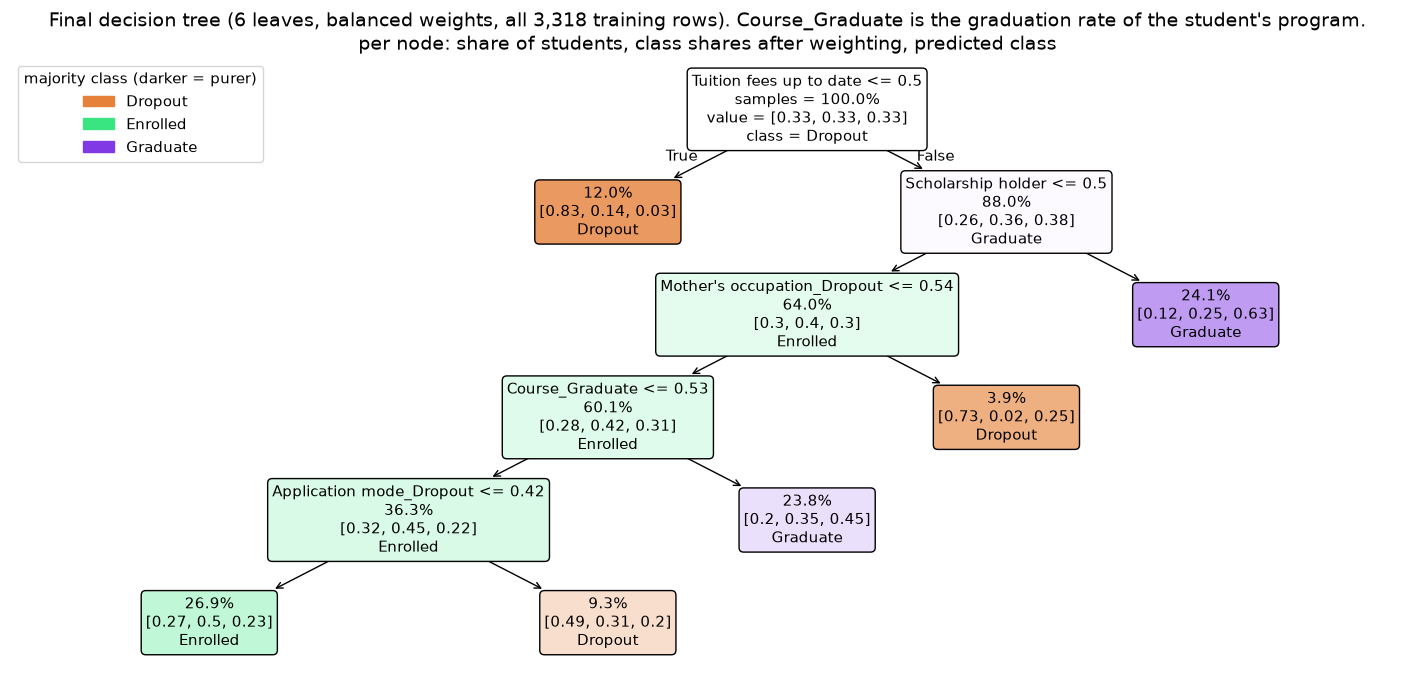

Mother's occupation_Dropout <= 0.54: 1, 10, 122, 123, 131, 132, 134, 141, 143, 144, 151, 152, 153, 171, 173, 175, 191, 192, 193, 194, 2, 3, 4, 5, 6, 7, 8, 9
Mother's occupation_Dropout >  0.54: 0, 90, 99

Course_Graduate <= 0.53: Advertising & Marketing Mgmt., Agronomy, Animation & Multimedia Design, Basic Education, Biofuel Production Tech., Equinculture, Informatics Eng., Management, Management (evening), Oral Hygiene, Tourism, Veterinary Nursing
Course_Graduate >  0.53: Communication Design, Journalism & Communication, Nursing, Social Service, Social Service (evening)

Application mode_Dropout <= 0.42: 1, 10, 15, 16, 17, 18, 42, 43, 44, 5, 51, 53, 57
Application mode_Dropout >  0.42: 2, 26, 27, 39, 7



Target,students,Dropout,Enrolled,Graduate,predicted
rule,,,,,
Tuition fees up to date = 0,397,0.866,0.081,0.053,Dropout
Tuition fees up to date = 1 & Scholarship holder = 1,799,0.099,0.113,0.788,Graduate
Tuition fees up to date = 1 & Scholarship holder = 0 & Mother's occupation_Dropout > 0.54,129,0.643,0.008,0.349,Dropout
Tuition fees up to date = 1 & Scholarship holder = 0 & Mother's occupation_Dropout <= 0.54 & Course_Graduate > 0.53,790,0.178,0.178,0.643,Graduate
Tuition fees up to date = 1 & Scholarship holder = 0 & Mother's occupation_Dropout <= 0.54 & Course_Graduate <= 0.53 & Application mode_Dropout <= 0.42,932,0.300,0.304,0.396,Enrolled
Tuition fees up to date = 1 & Scholarship holder = 0 & Mother's occupation_Dropout <= 0.54 & Course_Graduate <= 0.53 & Application mode_Dropout > 0.42,271,0.513,0.177,0.310,Dropout


,mean,sd
Tuition fees up to date,0.055,0.009
Course,0.046,0.010
Scholarship holder,0.024,0.008
Mother's occupation,0.018,0.007
Application mode,0.013,0.009
Marital status,0.000,0.000
Application order,0.000,0.000
Daytime/evening attendance,0.000,0.000


root split over 20 bootstrap refits: {'Tuition fees up to date': 20}
columns the tree splits on, out of 20 refits: {'Course': 20, 'Tuition fees up to date': 20, 'Scholarship holder': 19, "Mother's occupation": 14, 'Age at enrollment': 7, 'Application mode': 6, 'Previous qualification': 6, "Mother's qualification": 2, "Father's occupation": 1, 'Previous qualification (grade)': 1}


In [9]:
# Q2.3: the submitted tree drawn in full, what its rate splits mean, which columns the holdout score depends on, and how stable it is.
from matplotlib.patches import Patch
from sklearn.tree._export import _color_brew   # the colours plot_tree gives each class, for the legend

COURSE_NAMES = {33: "Biofuel Production Tech.", 171: "Animation & Multimedia Design", 8014: "Social Service (evening)",
                9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing", 9119: "Informatics Eng.",
                9130: "Equinculture", 9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
                9556: "Oral Hygiene", 9670: "Advertising & Marketing Mgmt.", 9773: "Journalism & Communication",
                9853: "Basic Education", 9991: "Management (evening)"}
final_tree, encoder = dt_final[-1], dt_final[0].named_transformers_["targetencoder"]
feature_names = dt_final[:-1].get_feature_names_out()   # a rate column is named column_Outcome, e.g. Course_Graduate
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(final_tree, feature_names=feature_names, class_names=dt_final.classes_, filled=True, impurity=False,
          proportion=True, rounded=True, precision=2, label="root", fontsize=11, ax=ax)
ax.legend(handles=[Patch(color=np.array(c) / 255, label=k) for c, k in zip(_color_brew(3), dt_final.classes_)],
          title="majority class (darker = purer)", loc="upper left", fontsize=11)
ax.set_title(f"Final decision tree ({final_tree.get_n_leaves()} leaves, balanced weights, all 3,318 training rows). "
             "Course_Graduate is the graduation rate of the student's program.\n"
             "per node: share of students, class shares after weighting, predicted class", fontsize=14)
plt.show()

# A rate split sorts codes into two groups. List the codes on each side, using the rates learned from all training rows.
rate_of = {f"{c}_{k}": pd.Series(encoder.encodings_[j + i * len(encoder.classes_)], index=encoder.categories_[i])
           for i, c in enumerate(NOMINAL) for j, k in enumerate(encoder.classes_)}
t = final_tree.tree_
for node in np.flatnonzero(t.children_left != -1):
    name = feature_names[t.feature[node]]
    if name in rate_of:
        label = (lambda code: COURSE_NAMES[code]) if name.startswith("Course_") else (lambda code: str(code))
        low, high = (sorted(label(c) for c in rate_of[name].index[side])
                     for side in (rate_of[name] <= t.threshold[node], rate_of[name] > t.threshold[node]))
        print(f"{name} <= {t.threshold[node]:.2f}: {', '.join(low)}\n{name} >  {t.threshold[node]:.2f}: {', '.join(high)}\n")


def leaf_rules(fitted_tree, names):
    """The conditions on the path to each leaf, with 0/1 columns written as '= 0' or '= 1'."""
    t, rules = fitted_tree.tree_, {}

    def walk(node, conds):
        if t.children_left[node] == -1:
            rules[node] = " & ".join(conds)
            return
        name, thr = names[t.feature[node]], t.threshold[node]
        if name in BINARY:
            left, right = f"{name} = 0", f"{name} = 1"
        else:
            digits = 2 if name in rate_of else 1
            left, right = f"{name} <= {thr:.{digits}f}", f"{name} > {thr:.{digits}f}"
        walk(t.children_left[node], conds + [left])
        walk(t.children_right[node], conds + [right])

    walk(0, [])
    return rules


# Every leaf of the final tree: its rule, how many training students reach it, and their actual (unweighted) outcomes.
leaf_id = final_tree.apply(dt_final[:-1].transform(X_train))
leaf_table = pd.crosstab(leaf_id, y_train, normalize="index")[CLASSES]
leaf_table.insert(0, "students", pd.Series(leaf_id).value_counts())
leaf_table["predicted"] = final_tree.classes_[t.value[leaf_table.index, 0].argmax(axis=1)]
leaf_table.index = [leaf_rules(final_tree, feature_names)[i] for i in leaf_table.index]
with pd.option_context("display.max_colwidth", 200):
    display(leaf_table.rename_axis("rule"))


def original_column(name):
    """Map a rate column such as 'Course_Graduate' back to the column it came from."""
    return next((c for c in NOMINAL if name.startswith(c + "_")), name)


# Permutation importance on the holdout, for the tree fit on the development rows (the full refit has seen the holdout).
perm_tree = permutation_importance(dt_dev, X_hold, y_hold, scoring="f1_macro", n_repeats=20, random_state=SEED)
perm_tree = pd.DataFrame({"mean": perm_tree.importances_mean, "sd": perm_tree.importances_std},
                         index=X_hold.columns).drop(index="International").sort_values("mean", ascending=False)
display(perm_tree.head(8).round(3))

# Refit the chosen settings on 20 bootstrap samples of the training rows.
rng = np.random.default_rng(SEED)
roots, used = [], []
for b in range(20):
    rows = rng.integers(0, len(X_train), len(X_train))
    boot = clone(dt_final).fit(X_train.iloc[rows], y_train.iloc[rows])
    names = boot[:-1].get_feature_names_out()
    roots.append(original_column(names[boot[-1].tree_.feature[0]]))
    used.append(sorted({original_column(names[f]) for f in boot[-1].tree_.feature if f >= 0}))
print("root split over 20 bootstrap refits:", pd.Series(roots).value_counts().to_dict())
print("columns the tree splits on, out of 20 refits:", pd.Series([c for u in used for c in u]).value_counts().to_dict())

**Written response: Q2.3**

- Tuition comes first. The 397 students behind on fees go to a Dropout leaf, and 0.866 of them dropped out. Paid-up scholarship holders go to a Graduate leaf (799 students, 0.788 graduated). For paid-up students without a scholarship the tree mostly looks at the program. Those in the five programs with a graduation rate above 0.53 (Nursing, both Social Service programs, Communication Design, Journalism) are predicted Graduate, and 0.643 graduated. In the other twelve programs, students who applied through a high-dropout route, mainly "over 23 years old" and "holders of other higher courses", are predicted Dropout (0.513 dropped out).
- The top of the tree is stable. Tuition was the root split in all 20 bootstrap refits, and tuition and the program were used in all 20 (scholarship in 19). Permutation importance on the holdout agrees: tuition 0.055, program 0.046, scholarship 0.024, mother's occupation 0.018, application mode 0.013, and 0.000 for every column the tree doesn't use.
- Two leaves deserve less trust. The Enrolled leaf holds 932 students, but only 0.304 of them were Enrolled and 0.396 graduated. Balancing alone puts the label there, and holdout Enrolled precision is 0.276. The mother's occupation split sends 129 students to Dropout on codes 0, 90 and 99, which the bundle doesn't describe, so we can't say what it measures, and it appears in only 14 of the 20 refits. All of it is association. Falling behind on fees probably signals money trouble that also drives dropout, so the tree can't tell us that enforcing payment would keep students enrolled. A program's rate also describes these cohorts, not what the program would do for a different student.

## Q2.4. Submit your tree's predictions to Kaggle

**5 points**

Write your final tree's predictions for `X_test` with `write_submission(predictions, "dt")`, and upload `submissions/submission_dt.csv` to the [Decision Tree competition](https://www.kaggle.com/t/e50d66fd164642fd98f915f0b89970d3). The link is an invitation: open it while signed in to Kaggle to join. In the written response, give your Kaggle team name and public leaderboard score.

In [10]:
# Q2.4: the final tree (refit on all training rows in Q2.2) predicts the 1,106 test students.
write_submission(dt_final.predict(X_test), "dt")

wrote submissions/submission_dt.csv: 1106 rows, {'Graduate': 504, 'Enrolled': 329, 'Dropout': 273}


In [11]:
grader.check("q2_4")

q2_4 results: All test cases passed!

**Written response: Q2.4**

- Kaggle team name: **TT**
- Public leaderboard score (macro-F1): **0.55032**

# Part 3. Model 2: an ensemble of your choice

Your second model is an ensemble of your choice: any ensemble method taught in lecture, implemented with scikit-learn. You must be able to explain how it works. The Kaggle Rules page states the rule in full.

## Q3.1. Prepare the data

**5 points**

Prepare the data for your ensemble. Reusing your Q2.1 preprocessing is fine if it suits this model. In the written response, explain each preprocessing decision and why it suits the ensemble you chose.

In [12]:
# Q3.1: one preparation per member of the ensemble, each suited to how that model reads a column.
forest_prep = outcome_rates   # the tree's preparation: International dropped, each code replaced by its outcome rates
boost_prep = make_column_transformer(("passthrough", KEPT), verbose_feature_names_out=False).set_output(transform="pandas")
logit_prep = make_column_transformer(   # one-hot codes, and every other column on a common scale for the penalty
    (OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist", sparse_output=False), NOMINAL),
    (StandardScaler(), OTHER), verbose_feature_names_out=False)
boost_probe = HistGradientBoostingClassifier(categorical_features=NOMINAL, random_state=SEED).fit(boost_prep.fit_transform(X_dev), y_dev)
print(f"columns each member sees: forest {forest_prep.fit(X_dev, y_dev).transform(X_dev).shape[1]}, "
      f"boosting {boost_prep.transform(X_dev).shape[1]} ({int(boost_probe.is_categorical_.sum())} read as categories), "
      f"logistic regression {logit_prep.fit(X_dev).transform(X_dev).shape[1]}")
print("most levels in one categorical column:", X_train[NOMINAL].nunique().max(), "(boosting allows up to 255)")

columns each member sees: forest 38, boosting 20 (9 read as categories), logistic regression 90
most levels in one categorical column: 41 (boosting allows up to 255)


**Written response: Q3.1**

- Our ensemble is a vote of three models, and each gets the preparation that fits how it reads a column. All three drop International as a copy of Nationality, and nothing needs imputing.
- The random forest reuses the tree's preparation: codes become outcome rates and nothing is scaled (38 columns). Gradient boosting (HistGradientBoostingClassifier) gets the raw columns and treats the 9 code columns as categories, so a split can send any group of codes one way. Our largest code column has 41 levels, under its limit of 255. It treats an unseen code as missing, and since training had no missing values, that goes to whichever side of a split held more training students.
- Logistic regression multiplies each column by a coefficient, so it would read a code number as a quantity. It gets one-hot columns (codes held by under 30 students pooled) and the other columns standardized, 90 columns in all. Standardizing matters here and not for the trees, because the ridge penalty shrinks every coefficient by the same rule, which is only even-handed when the columns share a scale. Each preparation sits inside its model's pipeline, so it is refit on every training fold.

## Q3.2. Choose, justify and tune your ensemble

**8 points**

Select your final ensemble. In the written response, explain which ensemble you chose, how it makes a prediction, and why you expected it to improve on your tree; then what you tuned, how you estimated performance on students the model has not seen, and the evidence that led to your final choice.

In [13]:
# Q3.2: three kinds of model tuned on the same five folds as the tree, then a vote that averages their probabilities.
ens_pipe = Pipeline([("prep", forest_prep), ("model", RandomForestClassifier())])
ens_grid = [
    {"prep": [forest_prep],
     "model": [RandomForestClassifier(n_estimators=300, criterion="gini", class_weight="balanced_subsample", n_jobs=1,
                                      random_state=SEED)],
     "model__max_features": [3, 6, 12, 24],   # of the 38 columns; 6 is the square root
     "model__min_samples_leaf": [5, 10, 20]},
    {"prep": [boost_prep],
     "model": [HistGradientBoostingClassifier(learning_rate=0.05, min_samples_leaf=20, class_weight="balanced",
                                              categorical_features=NOMINAL, random_state=SEED)],
     "model__max_iter": [25, 50, 100, 200],
     "model__max_leaf_nodes": [7, 15, 31]},
    {"prep": [logit_prep],
     "model": [LogisticRegression(class_weight="balanced", max_iter=5000)],
     "model__C": [0.01, 0.03, 0.1, 0.3, 1.0]},   # smaller C is a stronger ridge penalty
]
FAMILY = {"RandomForestClassifier": "random forest", "HistGradientBoostingClassifier": "gradient boosting",
          "LogisticRegression": "logistic regression"}
ens_search = GridSearchCV(ens_pipe, ens_grid, scoring="f1_macro", cv=cv, refit=False, n_jobs=-1).fit(X_dev, y_dev)
ens_res = pd.DataFrame(ens_search.cv_results_)
ens_res["family"] = [FAMILY[type(p["model"]).__name__] for p in ens_res["params"]]
ens_res["settings"] = [", ".join(f"{k.split('__')[1]}={v}" for k, v in p.items() if k.startswith("model__"))
                       for p in ens_res["params"]]
cols = ["family", "settings", "mean_test_score", "std_test_score"]
display(ens_res.sort_values("mean_test_score", ascending=False).groupby("family")[cols].head(3))

# The ensemble: each family's best setting, combined by averaging the three models' class probabilities (a soft vote).
best_of = ens_res.groupby("family")["mean_test_score"].idxmax()
members = [(family, clone(ens_pipe).set_params(**ens_res.loc[i, "params"])) for family, i in best_of.items()]
print("each family's best setting refit without class weights, CV macro-F1:",
      {family: f"{cross_val_score(clone(model).set_params(model__class_weight=None), X_dev, y_dev, cv=cv, scoring='f1_macro', n_jobs=-1).mean():.3f}"
       for family, model in members})
vote = VotingClassifier(members, voting="soft")
fold_cols = [f"split{i}_test_score" for i in range(5)]
folds = pd.DataFrame({family: ens_res.loc[i, fold_cols].to_numpy(float) for family, i in best_of.items()},
                     index=[f"fold {i + 1}" for i in range(5)])
folds["vote of the three"] = cross_val_score(vote, X_dev, y_dev, cv=cv, scoring="f1_macro", n_jobs=-1)
folds["tree"] = tree_res.loc[tree_search.best_index_, fold_cols].to_numpy(float)
display(pd.concat([folds, folds.agg(["mean", "std"])]).round(3))

# Five folds cannot separate models this close, so repeat the comparison on 20 new folds (5 folds, 4 different shuffles).
more_folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED + 1)
more = pd.DataFrame({name: cross_val_score(model, X_dev, y_dev, cv=more_folds, scoring="f1_macro", n_jobs=-1)
                     for name, model in members + [("vote of the three", vote)]})
lead = more[["vote of the three"]].to_numpy() - more.drop(columns="vote of the three")
check = pd.DataFrame({"mean macro-F1 on 20 folds": more.mean().drop("vote of the three"),
                      "vote minus this model": lead.mean(), "folds where the vote is ahead": (lead > 0).sum()})
display(check.round(3))
print(f"vote of the three: mean macro-F1 on 20 folds {more['vote of the three'].mean():.3f}")

# Fold by fold against the tree: the same five folds, so the differences are paired.
paired = folds[["tree", "vote of the three"]].rename(columns={"vote of the three": "ensemble"})
paired["ensemble - tree"] = paired["ensemble"] - paired["tree"]
display(paired.round(3))

# The estimate for unseen students: the vote, fit on the development rows, on the holdout.
ens_dev = clone(vote).fit(X_dev, y_dev)
ens_hold_pred = ens_dev.predict(X_hold)
print(f"holdout macro-F1 {f1_score(y_hold, ens_hold_pred, average='macro'):.3f}")
print(classification_report(y_hold, ens_hold_pred, digits=3))
# For reference only, since the choice was made on the folds above: each member alone on the same holdout students.
member_pred = pd.DataFrame({name: ens_dev.classes_[m.predict(X_hold)] for name, m in ens_dev.named_estimators_.items()},
                           index=X_hold.index)
print("each member alone on the holdout (not used for any choice):",
      {name: f"{f1_score(y_hold, member_pred[name], average='macro'):.3f}" for name in member_pred})

# The ensemble we submit: the same three settings, refit on all 3,318 training rows.
ens_final = clone(vote).fit(X_train, y_train)

,family,settings,mean_test_score,std_test_score
7,random forest,"max_features=12, min_samples_leaf=10",0.574,0.002
6,random forest,"max_features=12, min_samples_leaf=5",0.571,0.010
16,gradient boosting,"max_iter=50, max_leaf_nodes=15",0.569,0.019
15,gradient boosting,"max_iter=50, max_leaf_nodes=7",0.569,0.021
10,random forest,"max_features=24, min_samples_leaf=10",0.568,0.004
19,gradient boosting,"max_iter=100, max_leaf_nodes=15",0.568,0.020
25,logistic regression,C=0.03,0.561,0.018
27,logistic regression,C=0.3,0.560,0.014
28,logistic regression,C=1.0,0.560,0.012


each family's best setting refit without class weights, CV macro-F1: {'gradient boosting': '0.539', 'logistic regression': '0.508', 'random forest': '0.498'}


,gradient boosting,logistic regression,random forest,vote of the three,tree
fold 1,0.565,0.568,0.578,0.567,0.554
fold 2,0.600,0.582,0.574,0.599,0.576
fold 3,0.553,0.535,0.572,0.560,0.522
fold 4,0.547,0.546,0.572,0.573,0.543
fold 5,0.579,0.573,0.576,0.585,0.549
mean,0.569,0.561,0.574,0.577,0.549
std,0.021,0.020,0.002,0.016,0.020


,mean macro-F1 on 20 folds,vote minus this model,folds where the vote is ahead
gradient boosting,0.572,0.008,15
logistic regression,0.560,0.020,17
random forest,0.571,0.009,16


vote of the three: mean macro-F1 on 20 folds 0.580


,tree,ensemble,ensemble - tree
fold 1,0.554,0.567,0.013
fold 2,0.576,0.599,0.023
fold 3,0.522,0.560,0.038
fold 4,0.543,0.573,0.031
fold 5,0.549,0.585,0.036


holdout macro-F1 0.570
              precision    recall  f1-score   support

     Dropout      0.663     0.545     0.598       213
    Enrolled      0.333     0.479     0.393       119
    Graduate      0.736     0.705     0.720       332

    accuracy                          0.613       664
   macro avg      0.577     0.576     0.570       664
weighted avg      0.640     0.613     0.622       664

each member alone on the holdout (not used for any choice): {'gradient boosting': '0.570', 'logistic regression': '0.545', 'random forest': '0.571'}


**Written response: Q3.2**

- We chose a soft vote of three models taught in the course: a random forest and gradient boosting (the bagging, random forest and boosting lectures) and logistic regression (lectures 11 and 12). Each model gives every student three class probabilities. The vote averages them and predicts the class with the largest average. The forest averages 300 trees, each grown on a bootstrap sample with 12 random columns tried per split. Boosting adds 50 small trees in sequence, each fit to the errors left by the ones before. Logistic regression is linear, with a ridge penalty. All three use balanced weights.
- We expected it to beat the tree because our tree stops at 6 leaves (bigger ones overfit, 0.472 in validation with no limits), while a forest or boosting can use many more splits by averaging trees or adding small corrections. We expected the vote to beat its members because models built so differently make different mistakes, and averaging cancels some of them.
- On the tree's five folds we tuned the forest's columns per split (3 to 24) and leaf size (5 to 20), boosting's rounds (25 to 200) and leaves (7 to 31), and the logistic penalty C (0.01 to 1). The best of each scored 0.574, 0.569 and 0.561, with all three optima inside their grids, and without class weights the same settings fall to 0.498, 0.539 and 0.508. The vote scored 0.577. Five folds can't separate models this close, so we repeated the comparison on 20 new folds: the vote averaged 0.580 against 0.571, 0.572 and 0.560, and led each member on at least 15 of the 20. The holdout, scored after these choices, gives the vote 0.570 and its members 0.571, 0.570 and 0.545. Those gaps are far inside the holdout's noise (Q4.1), so the holdout can't separate the vote from its two best members, and it doesn't confirm the gain the folds show. The vote beat the tree on all five folds (by 0.013 to 0.038).

## Q3.3. Interpret your ensemble

**7 points**

Interpret your final ensemble. In the written response, explain what it tells you about which students drop out, remain enrolled, or graduate, and how much you trust that reading.

,ensemble,ensemble sd,tree,tree sd
Tuition fees up to date,0.052,0.010,0.055,0.009
Course,0.047,0.012,0.046,0.010
Scholarship holder,0.026,0.008,0.024,0.008
Application mode,0.025,0.010,0.013,0.009
Father's occupation,0.017,0.005,0.000,0.000
Age at enrollment,0.011,0.006,0.000,0.000
Marital status,0.010,0.003,0.000,0.000
Mother's occupation,0.010,0.008,0.018,0.007
Debtor,0.009,0.005,0.000,0.000
Previous qualification,0.009,0.004,0.000,0.000


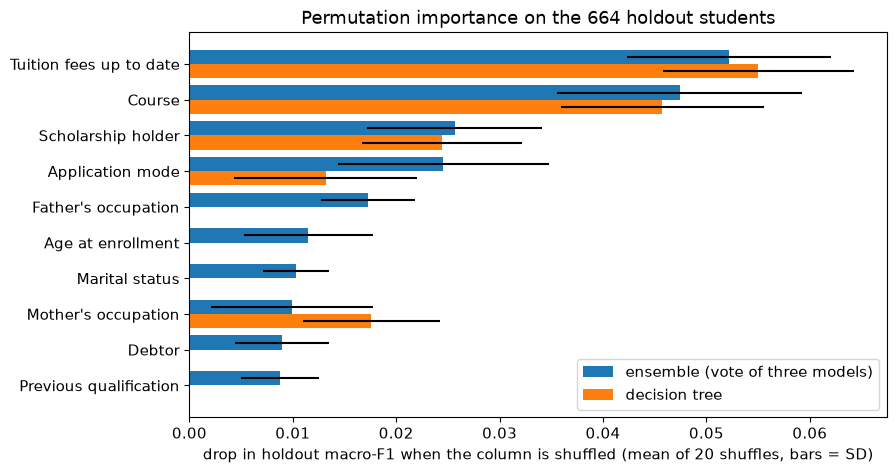

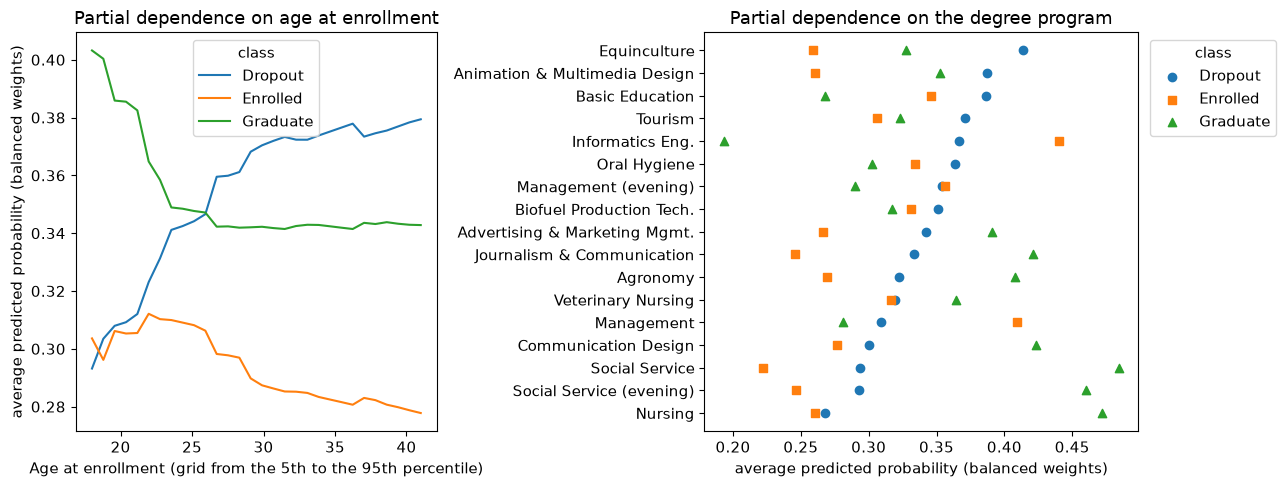

age 18 to 41: P(Dropout) 0.29 to 0.38, P(Enrolled) 0.30 to 0.28, P(Graduate) 0.40 to 0.34


,Dropout,Enrolled,Graduate
Nursing,0.267,0.261,0.472
Social Service (evening),0.293,0.247,0.460
Social Service,0.294,0.222,0.484
Communication Design,0.300,0.277,0.423
Management,0.309,0.410,0.281
Veterinary Nursing,0.319,0.316,0.364
Agronomy,0.323,0.269,0.408
Journalism & Communication,0.333,0.246,0.421
Advertising & Marketing Mgmt.,0.342,0.267,0.391
Biofuel Production Tech.,0.351,0.331,0.317


In [14]:
# Q3.3: which columns the ensemble's holdout score depends on (next to the tree's), and how two of them move each class.
perm_ens = permutation_importance(ens_dev, X_hold, y_hold, scoring="f1_macro", n_repeats=20, random_state=SEED, n_jobs=-1)
perm_ens = pd.DataFrame({"mean": perm_ens.importances_mean, "sd": perm_ens.importances_std},
                        index=X_hold.columns).drop(index="International")
perm_both = pd.DataFrame({"ensemble": perm_ens["mean"], "ensemble sd": perm_ens["sd"],
                          "tree": perm_tree["mean"], "tree sd": perm_tree["sd"]}).sort_values("ensemble", ascending=False)
display(perm_both.head(10).round(3))

top = perm_both.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))
ax.barh(y + 0.2, top["ensemble"], height=0.4, xerr=top["ensemble sd"], label="ensemble (vote of three models)")
ax.barh(y - 0.2, top["tree"], height=0.4, xerr=top["tree sd"], label="decision tree")
ax.set_yticks(y, top.index)
ax.set(xlabel="drop in holdout macro-F1 when the column is shuffled (mean of 20 shuffles, bars = SD)",
       title="Permutation importance on the 664 holdout students")
ax.legend(loc="lower right")
plt.show()

# Partial dependence: the average predicted probability of each class as one column varies, the others as observed.
pd_age = partial_dependence(ens_dev, X_dev.astype({"Age at enrollment": float}), ["Age at enrollment"], grid_resolution=30)
pd_course = partial_dependence(ens_dev, X_dev, ["Course"], categorical_features=["Course"])
course_pd = pd.DataFrame(pd_course["average"].T, columns=ens_dev.classes_,
                         index=[COURSE_NAMES[c] for c in pd_course["grid_values"][0]]).sort_values("Dropout")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.2]})
for k, cls in enumerate(ens_dev.classes_):
    axes[0].plot(pd_age["grid_values"][0], pd_age["average"][k], label=cls)
axes[0].set(xlabel="Age at enrollment (grid from the 5th to the 95th percentile)",
            ylabel="average predicted probability (balanced weights)", title="Partial dependence on age at enrollment")
axes[0].legend(title="class")
yy = np.arange(len(course_pd))
for cls, marker in [("Dropout", "o"), ("Enrolled", "s"), ("Graduate", "^")]:
    axes[1].scatter(course_pd[cls], yy, marker=marker, label=cls)
axes[1].set_yticks(yy, course_pd.index)
axes[1].set(xlabel="average predicted probability (balanced weights)", title="Partial dependence on the degree program")
axes[1].legend(title="class", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()
g, avg = pd_age["grid_values"][0], pd_age["average"]
print(f"age {g[0]:.0f} to {g[-1]:.0f}: P(Dropout) {avg[0][0]:.2f} to {avg[0][-1]:.2f}, "
      f"P(Enrolled) {avg[1][0]:.2f} to {avg[1][-1]:.2f}, P(Graduate) {avg[2][0]:.2f} to {avg[2][-1]:.2f}")
display(course_pd)

**Written response: Q3.3**

- On the holdout, permutation importance ranks tuition first (0.052), then the program (0.047), scholarship (0.026), application mode (0.025) and father's occupation (0.017). By partial dependence, the average P(Dropout) ranges from 0.267 for Nursing to 0.414 for Equinculture. Informatics Engineering has P(Enrolled) 0.440 but P(Graduate) 0.193, which looks like students who finish late rather than quit. Moving age from 18 to 41 raises P(Dropout) from 0.29 to 0.38 and lowers P(Graduate) from 0.40 to 0.34.
- The tree and the ensemble agree on the top three columns and almost on their sizes (tuition 0.055 and 0.052, program 0.046 and 0.047, scholarship 0.024 and 0.026), so we trust those most. The ensemble then spreads small amounts over columns the tree never uses, such as father's occupation, age and marital status.
- Below the top four, the order isn't reliable. Every other column scores 0.017 or less, with SDs up to 0.008, and columns that overlap share credit: application mode 39 means over 23, so shuffling age alone costs only 0.011. The partial dependence curves average balanced-weight predictions, so they overstate Enrolled, and they mix values that rarely occur together, like a 41-year-old with a school leaver's profile. A vote is also harder to read than one model, since these numbers describe an average of three models and not a rule anyone can follow. As with the tree, they are associations measured on 664 students, not effects of changing anything.

## Q3.4. Submit your ensemble's predictions to Kaggle

**5 points**

Write your final ensemble's predictions for `X_test` with `write_submission(predictions, "ensemble")`, and upload `submissions/submission_ensemble.csv` to the [Ensemble competition](https://www.kaggle.com/t/49d8d5280406448a80a62786912c4595). The link is an invitation: open it while signed in to Kaggle to join. In the written response, give your Kaggle team name and public leaderboard score.

In [15]:
# Q3.4: the final ensemble (refit on all training rows in Q3.2) predicts the 1,106 test students.
write_submission(ens_final.predict(X_test), "ensemble")

wrote submissions/submission_ensemble.csv: 1106 rows, {'Graduate': 496, 'Enrolled': 307, 'Dropout': 303}


In [16]:
grader.check("q3_4")

q3_4 results: All test cases passed!

**Written response: Q3.4**

- Kaggle team name: **TerrySu1016**
- Public leaderboard score (macro-F1): **0.59039**

# Part 4. Comparing your models

## Q4.1. Compare your models and make a recommendation

**12 points**

Compare your two models and recommend one. In the written response, make the case for your recommendation with evidence from your own output, and discuss whether and how a university should act on its predictions.

,holdout macro-F1,F1 Dropout,F1 Enrolled,F1 Graduate,accuracy,CV macro-F1 (dev folds)
decision tree,0.525,0.560,0.333,0.682,0.569,0.549
ensemble (vote),0.570,0.598,0.393,0.720,0.613,0.577


bootstrap SE of holdout macro-F1: tree 0.019, ensemble 0.020
ensemble minus tree, holdout macro-F1: 0.045; 95% bootstrap interval [0.014, 0.076]; share of resamples with the ensemble ahead 0.997
on the five CV folds the ensemble was ahead in 5 of 5, by 0.013 to 0.038


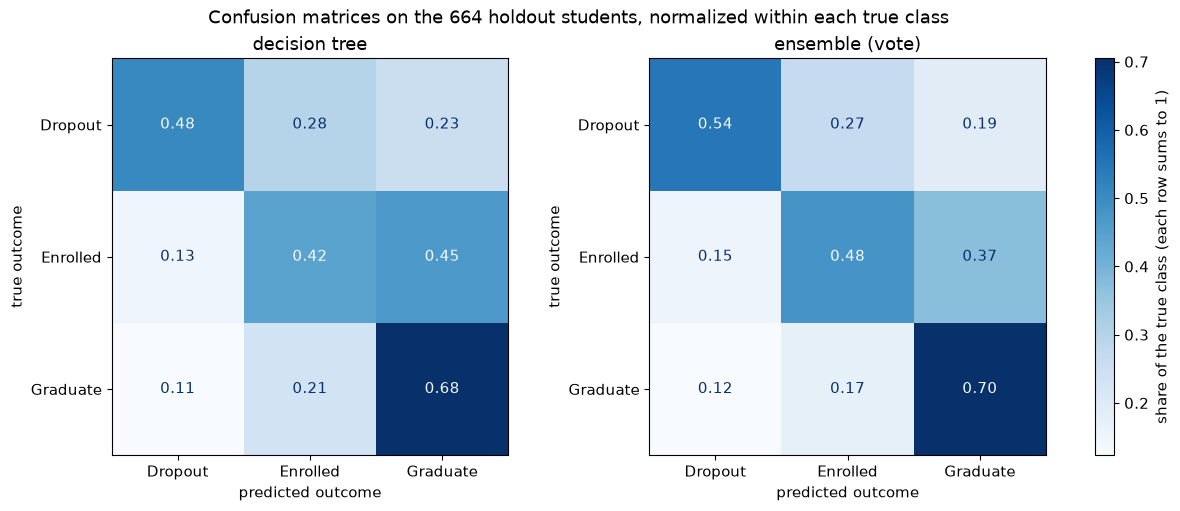

,students,actual dropouts,flagged as Dropout,Dropout recall,Dropout precision
group,,,,,
Gender: female,2154,543,447,0.538,0.653
Gender: male,1164,523,509,0.654,0.672
Scholarship holder: no,2483,964,905,0.627,0.667
Scholarship holder: yes,835,102,51,0.294,0.588
Age at enrollment: 17-19,1477,300,158,0.317,0.601
Age at enrollment: 20-24,991,296,224,0.490,0.647
Age at enrollment: 25+,850,470,574,0.838,0.686


the three members agree on 0.723 of the holdout students
flagged Dropout, all three members say Dropout: 130 students, 0.738 dropped out
flagged Dropout, the members disagree: 45 students, 0.444 dropped out


In [17]:
# Q4.1: both models on the same holdout students, with the uncertainty of the gap, and where each one errs.
models = {"decision tree": dt_hold_pred, "ensemble (vote)": ens_hold_pred}
summary = {}
for name, pred in models.items():
    f1s = f1_score(y_hold, pred, average=None, labels=CLASSES)
    summary[name] = {"holdout macro-F1": f1_score(y_hold, pred, average="macro"),
                     **{f"F1 {c}": v for c, v in zip(CLASSES, f1s)},
                     "accuracy": np.mean(pred == y_hold)}
summary["decision tree"]["CV macro-F1 (dev folds)"] = tree_res.loc[tree_search.best_index_, "mean_test_score"]
summary["ensemble (vote)"]["CV macro-F1 (dev folds)"] = folds["vote of the three"].mean()
display(pd.DataFrame(summary).T.round(3))

# Paired bootstrap: resample the 664 holdout students and recompute both macro-F1s on the same resample.
rng = np.random.default_rng(SEED)
truth, p_tree, p_ens = y_hold.to_numpy(), dt_hold_pred, ens_hold_pred
boot = []
for _ in range(2000):
    i = rng.integers(0, len(truth), len(truth))
    boot.append((f1_score(truth[i], p_tree[i], average="macro"), f1_score(truth[i], p_ens[i], average="macro")))
boot = np.array(boot)
gaps = boot[:, 1] - boot[:, 0]
print(f"bootstrap SE of holdout macro-F1: tree {boot[:, 0].std():.3f}, ensemble {boot[:, 1].std():.3f}")
print(f"ensemble minus tree, holdout macro-F1: {f1_score(truth, p_ens, average='macro') - f1_score(truth, p_tree, average='macro'):.3f}; "
      f"95% bootstrap interval [{np.quantile(gaps, 0.025):.3f}, {np.quantile(gaps, 0.975):.3f}]; "
      f"share of resamples with the ensemble ahead {np.mean(gaps > 0):.3f}")
print(f"on the five CV folds the ensemble was ahead in {int((paired['ensemble - tree'] > 0).sum())} of 5, "
      f"by {paired['ensemble - tree'].min():.3f} to {paired['ensemble - tree'].max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, (name, pred) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_hold, pred, labels=CLASSES, normalize="true", values_format=".2f",
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set(title=name, xlabel="predicted outcome", ylabel="true outcome")
fig.colorbar(axes[1].images[0], ax=axes, label="share of the true class (each row sums to 1)")
fig.suptitle("Confusion matrices on the 664 holdout students, normalized within each true class")
plt.show()

# Dropout recall and precision by group, from out-of-fold predictions of the recommended model on all 3,318 rows.
oof = pd.Series(cross_val_predict(clone(ens_dev), X_train, y_train, cv=cv), index=X_train.index)
groups = {"Gender": X_train["Gender"].map({0: "female", 1: "male"}),
          "Scholarship holder": X_train["Scholarship holder"].map({0: "no", 1: "yes"}),
          "Age at enrollment": pd.cut(X_train["Age at enrollment"], [0, 19, 24, 100], labels=["17-19", "20-24", "25+"]).astype(str)}
rows = []
for gname, g in groups.items():
    for level in sorted(g.unique()):
        m = g == level
        is_drop, flagged = y_train[m] == "Dropout", oof[m] == "Dropout"
        rows.append({"group": f"{gname}: {level}", "students": int(m.sum()), "actual dropouts": int(is_drop.sum()),
                     "flagged as Dropout": int(flagged.sum()),
                     "Dropout recall": (is_drop & flagged).sum() / is_drop.sum(),
                     "Dropout precision": (is_drop & flagged).sum() / max(flagged.sum(), 1)})
display(pd.DataFrame(rows).set_index("group").round(3))


# How far to trust a Dropout flag: whether the three members' own holdout predictions (from Q3.2) agree.
agree = (member_pred.nunique(axis=1) == 1).to_numpy()
flag = ens_hold_pred == "Dropout"
print(f"the three members agree on {agree.mean():.3f} of the holdout students")
for label, m in [("all three members say Dropout", flag & agree), ("the members disagree", flag & ~agree)]:
    print(f"flagged Dropout, {label}: {m.sum()} students, {np.mean(y_hold[m] == 'Dropout'):.3f} dropped out")

**Written response: Q4.1**

- We recommend the ensemble. On the same 664 holdout students it scores 0.570 macro-F1 vs 0.525 for the tree (bootstrap 95% interval for the gap [0.014, 0.076], ahead in 99.7% of resamples). It led on all five CV folds, and it scored 0.59039 vs 0.55032 on Kaggle's public leaderboard (about 22% of the test rows). It is better on every class (F1 for Dropout 0.598 vs 0.560, Enrolled 0.393 vs 0.333, Graduate 0.720 vs 0.682). The tree is still the better way to explain the pattern. It has six leaves, and the ensemble agrees with it on fees, program and scholarships.
- A university should use the model only as an early-warning list that leads to support (advising, tutoring, help with fees), never for admissions, penalties or debt collection. The vote finds only 0.545 of the holdout dropouts, and about a third of the students it flags would not drop out (precision 0.663). Whether its members agree says which flags to trust. When all three say Dropout (130 students), 0.738 dropped out. When they disagree (45 students), only 0.444 did. Its Enrolled label is wrong more often than right (precision 0.333), so we wouldn't act on it.
- The errors are uneven. Out of fold, it catches 0.838 of dropouts aged 25 or older but 0.317 of those aged 17 to 19, 0.654 of male vs 0.538 of female dropouts, and 0.294 of scholarship holders who drop out. A program built on it would miss most young dropouts and needs other ways to reach them. The strongest columns are about money, so the response should be financial help, not sanctions. The data cover students who entered one Portuguese polytechnic from 2008/09 to 2018/19 (per the paper in data/), so the model has to be rechecked and recalibrated on the university's own recent students first.

## Wrap-up

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fbe8ff; border-color: #eed4db; border-width: 1px; border-radius: 3px; padding: 10px;">

* How many hours did you spend on this assignment? Store an int or float in `hours_spent_on_hw`. If you worked in a pair, report the average per person.
* Briefly describe how you used AI assistance and how you checked its contributions.
* (Optional) Which aspect of the assignment did you find most challenging?

</div>

In [18]:
# Report your hours here. Replace None with an int or float.
hours_spent_on_hw = 13

In [19]:
print("Notebook runtime, minutes:", round((time.time() - notebook_start) / 60, 1))

Notebook runtime, minutes: 1.8


**Written response: Wrap-up**

- We used Claude Code to write most of the code and a first draft of these answers. We checked its work by re-running the notebook from a restarted kernel, matching every number in the answers to the printed output, confirming that runs on three Linux machines with different processors write byte-identical submission files, and rewording the answers ourselves.
- The hardest part was getting an honest performance estimate while every choice was tuned on the same 3,318 rows. Keeping a holdout that no tuning step touched was our answer. We revised both models once after our first Kaggle submission, and made those choices on the development folds only.